# 02 — Exploratory Data Analysis (EDA)

## Project Overview

This notebook focuses on exploring and understanding the integrated climate datasets for dry spell prediction in Gadarif State, Sudan.

The analysis aims to:

- Understand the target variable distribution.
- Examine descriptive statistics of climate features.
- Investigate feature distributions and relationships.
- Explore temporal patterns and trends.
- Identify potential outliers and data quality issues.

The merged datasets prepared in the previous notebook will be used as the starting point for this analysis.

## 2.1.1 Environment Setup and Data Loading

In this section, we will initialize the project environment, import the required libraries, and load the previously integrated training and testing datasets.

The original merged datasets will be loaded without applying additional preprocessing or transformations.

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import (
    TRAIN_DIR,
    TEST_DIR,
    DATA_DIR,
    MODELS_DIR,
    REPORTS_DIR
)

print("Project root:", PROJECT_ROOT)

Project root: D:\Users\PC\Desktop\To the new pc\Elzero\ML-Projects\IndabaX2025-DrySpell-Challenge


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
from src.data_loader import (
    load_and_standardize_datasets,
    merge_datasets
)

### 2.1.2 Load and Merge Datasets

In this subsection, the original training and testing datasets are loaded and standardized using the reusable functions implemented in `src/data_loader.py`.

The individual datasets are then merged into two unified DataFrames, `train_merged` and `test_merged`, using the date column as the common key.

No additional preprocessing, imputation, or feature transformations will be applied at this stage.

In [5]:
# Load and standardize training datasets
train_datasets = load_and_standardize_datasets(TRAIN_DIR)

# Load and standardize testing datasets
test_datasets = load_and_standardize_datasets(TEST_DIR)

# Merge datasets
train_merged = merge_datasets(train_datasets)
test_merged = merge_datasets(test_datasets)

print("Training dataset shape:", train_merged.shape)
print("Testing dataset shape:", test_merged.shape)

Training dataset shape: (2214, 18)
Testing dataset shape: (738, 17)


#### Key Findings

- The training dataset contains **2,214 rows and 18 columns**.
- The testing dataset contains **738 rows and 17 columns**.
- Both datasets were successfully loaded and merged using the reusable functions in `src/data_loader.py`.
- The resulting shapes match the integration results obtained in Notebook 01.
- No additional preprocessing or feature transformations have been applied.

The datasets are ready for exploratory data analysis (EDA).

## 2.2 Target Variable Analysis

The target variable, `dryspell_warn_7d`, represents the prediction label for the dry spell warning task.

This section investigates the distribution of the target classes to understand their frequency, relative proportions, and potential class imbalance.

Understanding the target distribution is essential for selecting appropriate evaluation metrics and modeling strategies.

### 2.2.1 Target Distribution

This subsection examines the frequency and percentage of each class in the training dataset.

The analysis includes a numerical summary and a visualization of the target class distribution.

,Count,Percentage (%)
dryspell_warn_7d,,
0,1890,85.365854
1,324,14.634146


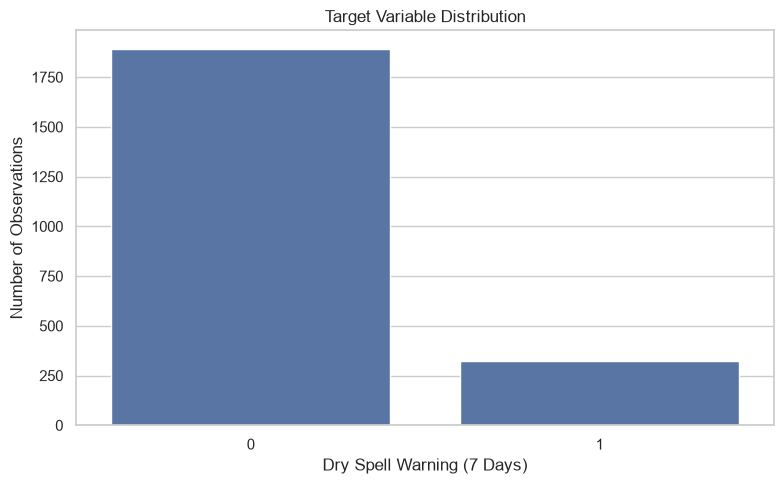

In [8]:
# Calculate target class counts
target_counts = train_merged["dryspell_warn_7d"].value_counts().sort_index()

# Calculate target class percentages
target_percentages = (
    train_merged["dryspell_warn_7d"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Combine results into a summary DataFrame
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages
})

display(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_merged,
    x="dryspell_warn_7d"
)

plt.title("Target Variable Distribution")
plt.xlabel("Dry Spell Warning (7 Days)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

#### Key Findings

- The target variable contains two classes: 0 and 1.
- Class 0 represents 1,890 observations (85.37%).
- Class 1 represents 324 observations (14.63%).
- The target distribution exhibits a noticeable class imbalance, with approximately 5.83 observations of Class 0 for every observation of Class 1.
- A majority-class baseline classifier would achieve approximately 85.37% accuracy while failing to identify any Class 1 observations.

This imbalance must be considered during model development and evaluation, particularly when selecting classification metrics.

### 2.2.2 Class Imbalance Analysis

This subsection quantifies the degree of class imbalance and examines the performance of a simple majority-class baseline.

The baseline classifier always predicts the majority class (Class 0). Its performance illustrates why accuracy alone may be misleading for this classification task.

In [9]:
# Calculate class imbalance ratio
majority_count = target_counts.max()
minority_count = target_counts.min()

imbalance_ratio = majority_count / minority_count

# Majority-class baseline
baseline_accuracy = majority_count / len(train_merged) * 100

print(f"Majority class count: {majority_count}")
print(f"Minority class count: {minority_count}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.2f}%")

print("\nBaseline classification behavior:")
print("Class 0 Recall: 100%")
print("Class 1 Recall: 0%")

Majority class count: 1890
Minority class count: 324
Imbalance ratio: 5.83:1
Majority-class baseline accuracy: 85.37%

Baseline classification behavior:
Class 0 Recall: 100%
Class 1 Recall: 0%
